# WAFER-GUARD: fixed version

This is my fixed version of the original notebook (`bnypi.ipynb`). The original reported F1 = 0.99, but it had 3 bugs that made that number fake:

1. **Data leakage.** The imputer and scaler were fit on ALL the data, SMOTE ran before the train/test split, and the split was random in time. So the model basically saw the test set during training. The test set was also 50% synthetic defects instead of the real ~6.6%.
2. **Broadcasting bug in the loss.** `reconstructed` is `[B, F]` but `batch_x` was `[B, 1, F]`. PyTorch silently turned the subtraction into `[B, B, F]`, so the reconstruction loss was comparing every wafer against every other wafer.
3. **Legacy probe station (PS-L) ignored.** `sensor_0 == 0.0` is a marker, not a reading, and on those wafers `sensor_1` is an error code (100/200/300). The original scaled and averaged them like normal numbers.

Most of the code now lives in `wafer_utils.py` so it can be tested (`pytest -q`). Everything I changed is explained in `AUDIT.md`.

**How the notebook is laid out**
- Part A (sections 1-7): the original model and settings with just the bugs fixed.
- Part B (sections 8-11): a small tuning round done properly (walk-forward CV on past data only, test set used once at the end) and a check on the legacy wafers.
- Section 12: charts. Section 13: release gate.

The whole notebook takes about 3 minutes on a laptop CPU.

## 0. Setup

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, roc_auc_score, average_precision_score,
                             classification_report, precision_recall_curve)
import joblib

import wafer_utils as wu
from wafer_utils import SEED

warnings.filterwarnings("ignore", category=RuntimeWarning)  # nanmean etc on empty columns
torch.use_deterministic_algorithms(True)
wu.seed_all(SEED)


os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
print("torch", torch.__version__)

torch 2.12.1+cpu


## 1. Load the data
Sorting by timestamp first because the fab drifts over time, and every split after this depends on the order.

In [2]:
df = pd.read_csv("secom_telemetry_modified.csv", parse_dates=["timestamp"])
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
assert df["timestamp"].is_monotonic_increasing

SENSOR_COLS = wu.get_sensor_cols(df)
y_all = (df["label"].to_numpy() == 1).astype(np.int64)   # 1 = defective, 0 = pass

print(f"{len(df)} wafers, {len(SENSOR_COLS)} sensors")
print(f"defect rate: {y_all.mean():.2%} ({y_all.sum()} fails)")
print(f"time span: {df.timestamp.min()} to {df.timestamp.max()}")

decile_rates = [c.mean() for c in np.array_split(y_all, 10)]
print("defect rate per tenth of the data (oldest -> newest):", [f"{r:.1%}" for r in decile_rates])

1567 wafers, 590 sensors
defect rate: 6.64% (104 fails)
time span: 2008-07-19 11:55:00 to 2008-10-17 06:07:00
defect rate per tenth of the data (oldest -> newest): ['12.7%', '15.3%', '8.9%', '4.5%', '1.3%', '5.7%', '1.3%', '6.4%', '8.3%', '1.9%']


The defect rate moves around a lot over time (13-15% at the start, 1-8% later). This is why a random split is a bad idea here, and also why the test window won't land on exactly 6.6%.

## 2. Split by time (fix for bug 1)
Oldest 60% = train, next 20% = validation (early stopping + picking the threshold), newest 20% = test. The test set is never resampled.

In [3]:
idx_tr, idx_va, idx_te = wu.time_split(len(df), (0.6, 0.2, 0.2))

# make sure nothing from the future ends up in training
assert df.timestamp[idx_tr].max() < df.timestamp[idx_va].min()
assert df.timestamp[idx_va].max() < df.timestamp[idx_te].min()

for name, ix in [("train", idx_tr), ("val", idx_va), ("test", idx_te)]:
    print(f"{name:5s} n={len(ix):4d}  defects={y_all[ix].sum():3d} ({y_all[ix].mean():.2%})  "
          f"{df.timestamp[ix].min()} -> {df.timestamp[ix].max()}")

train n= 940  defects= 76 (8.09%)  2008-07-19 11:55:00 -> 2008-09-20 05:34:00
val   n= 313  defects= 11 (3.51%)  2008-09-20 06:08:00 -> 2008-10-02 19:25:00
test  n= 314  defects= 17 (5.41%)  2008-10-02 20:54:00 -> 2008-10-17 06:07:00


## 3. Legacy probe station PS-L (fix for bug 3)
- `sensor_0 == 0.0` means the wafer went through PS-L. It's a flag, not a measurement.
- On those wafers `sensor_1` is a firmware error code (100 / 200 / 300), so it gets one-hot encoded instead of being treated as a number.

`wu.legacy_view()` only looks at one row at a time, so it can't leak anything between train and test.

In [4]:
is_leg, codes, _ = wu.legacy_view(df, SENSOR_COLS)
print(f"legacy PS-L wafers: {is_leg.sum()} ({is_leg.mean():.1%})")
print("code counts [100, 200, 300, unknown]:", codes.sum(axis=0).astype(int).tolist())
print("sensor_1 on normal wafers:   mean %.1f  std %.1f" % (df.sensor_1[~is_leg].mean(), df.sensor_1[~is_leg].std()))
print("sensor_1 if codes mixed in:  mean %.1f  std %.1f  <- what the original used" % (df.sensor_1.mean(), df.sensor_1.std()))
print(f"defect rate legacy vs normal: {y_all[is_leg].mean():.2%} vs {y_all[~is_leg].mean():.2%}")

legacy PS-L wafers: 146 (9.3%)
code counts [100, 200, 300, unknown]: [61, 35, 50, 0]
sensor_1 on normal wafers:   mean 2495.7  std 79.8
sensor_1 if codes mixed in:  mean 2280.5  std 675.3  <- what the original used
defect rate legacy vs normal: 0.00% vs 7.32%


Interesting: none of the 146 legacy wafers are defective. That could make a model learn "legacy = pass", which is probably just a coincidence in this data. I check this in section 11.

## 4. Preprocessing, fit on train only (fix for bugs 1 and 3)
`wu.Preprocessor` does the following, all learned from the **training rows only**:
- the sentinel / error code slots are set aside first so they never go into a mean or std
- drops sensors that are constant or more than 50% missing
- scales with the train mean/std and clips to +-10
- fills real gaps with the train median and adds a "was missing" column for sensors with 1%+ missing
- adds `is_legacy` + the one-hot code columns

The sentinel/code slots get a placeholder of 0, but their mask is 0 so the autoencoder is never asked to rebuild them. So no fake readings are used as targets.

In [5]:
prep = wu.Preprocessor().fit(df.iloc[idx_tr])
X_tr, M_tr = prep.transform(df.iloc[idx_tr])
X_va, M_va = prep.transform(df.iloc[idx_va])
X_te, M_te = prep.transform(df.iloc[idx_te])
y_tr, y_va, y_te = y_all[idx_tr], y_all[idx_va], y_all[idx_te]
F = X_tr.shape[1]

print(f"features: {F} = {prep.n_cont} sensors + {len(prep.flag_cols)} missing flags + 5 legacy columns")
j = prep.feature_names.index("sensor_1")
print(f"sensor_1 scaling learned from train: mean {prep.mean[j]:.1f}, std {prep.std[j]:.1f} (codes not included)")
print("shapes:", X_tr.shape, X_va.shape, X_te.shape)

features: 487 = 444 sensors + 38 missing flags + 5 legacy columns
sensor_1 scaling learned from train: mean 2494.9, std 85.7 (codes not included)
shapes: (940, 487) (313, 487) (314, 487)


## 5. Tensors, model and loss (fix for bug 2)
- `make_loader` no longer does `unsqueeze(1)`, so batches are `[B, F]`.
- `WaferSAE` is the same network as before, but `forward()` now refuses anything that isn't 2D (the original did `flatten` which hid the problem).
- `sae_loss` checks that `recon`, `x` and `mask` all have the same `[B, F]` shape and that logits and labels are both `[B]` before doing any math.
- Instead of SMOTE, the BCE loss uses `pos_weight = passes / fails` from the training set.

In [6]:
xb, mb, yb = next(iter(wu.make_loader(X_tr, M_tr, y_tr, shuffle=True)))
print("batch shapes: x", tuple(xb.shape), "| mask", tuple(mb.shape), "| y", tuple(yb.shape))

# quick check that the old shape now fails instead of silently broadcasting
try:
    wu.WaferSAE(F, 16, 4)(torch.zeros(4, 1, F))
    print("uh oh, this should have failed")
except AssertionError as e:
    print("good, [B,1,F] input is rejected:", e)

print("what the old code did:", tuple((torch.zeros(64, F) - torch.zeros(64, 1, F)).shape))

batch shapes: x (64, 487) | mask (64, 487) | y (64,)
good, [B,1,F] input is rejected: expected [B, F], got (4, 1, 487)
what the old code did: (64, 64, 487)


## 6. Train (Part A: original settings, bugs fixed)
Same size and optimiser as the original. I added early stopping on validation PR-AUC.

In [7]:
model, history = wu.train_sae(X_tr, M_tr, y_tr, X_va, y_va)

epoch 01 | total 2.0312 | recon 0.7943 | clf 1.2369 | val AP 0.0363


epoch 05 | total 0.7493 | recon 0.7087 | clf 0.0406 | val AP 0.0376


epoch 10 | total 0.6059 | recon 0.6037 | clf 0.0022 | val AP 0.0337
best epoch 3 (val AP 0.0398), pos_weight = 11.37


The training classification loss drops to almost 0 really quickly but validation PR-AUC doesn't go up. So the network is overfitting (940 wafers, only 76 defects, ~200k parameters). Part B tries to deal with this.

## 7. Threshold + test evaluation (Part A)
The original used 0.5 as the threshold, which only made sense on its fake 50/50 data. Here I pick the threshold with the best F1 on **validation**, then freeze it and run the test set once.

I report PR-AUC as the main metric because with ~5% defects, ROC-AUC and accuracy look good even for bad models. A random model's PR-AUC is just the defect rate, which makes it easy to compare against.

The test window has 5.41% defects (that's just what happened in those two weeks). I also convert precision/F1 to the dataset-wide 6.64% using the measured TPR/FPR, which doesn't involve resampling anything.

In [8]:
p_va = wu.predict_proba(model, X_va)
THRESHOLD_A = wu.pick_threshold(y_va, p_va)
print(f"validation PR-AUC {average_precision_score(y_va, p_va):.4f}, threshold = {THRESHOLD_A:.4f}")

p_te_A = wu.predict_proba(model, X_te)
res_A = wu.evaluate(y_te, p_te_A, THRESHOLD_A)
wu.show(res_A, "Part A: repaired SAE on the test window")
print()
print(classification_report(y_te, (p_te_A >= THRESHOLD_A).astype(int), target_names=["pass", "defect"], digits=4))

validation PR-AUC 0.0398, threshold = 0.0194
--- Part A: repaired SAE on the test window ---
n=314  defects=17  defect rate=5.41%
PR-AUC 0.0696 (random guess = 0.0541)   ROC-AUC 0.5389
F1 0.1364   precision 0.0845   recall 0.3529
confusion: TN=232  FP=65  FN=11  TP=6
at the dataset-wide 6.64% defect rate: precision 0.1029, F1 0.1593



              precision    recall  f1-score   support

        pass     0.9547    0.7811    0.8593       297
      defect     0.0845    0.3529    0.1364        17

    accuracy                         0.7580       314
   macro avg     0.5196    0.5670    0.4978       314
weighted avg     0.9076    0.7580    0.8201       314



### 7b. Is that result stable?
1. Retrain with 5 different seeds.
2. Logistic regression on the same features, as a sanity check: is the neural net actually better than something simple?

In [9]:
seed_rows = []
for s in range(5):
    m_s, _ = wu.train_sae(X_tr, M_tr, y_tr, X_va, y_va, seed=s, verbose=False)
    thr_s = wu.pick_threshold(y_va, wu.predict_proba(m_s, X_va))
    p_s = wu.predict_proba(m_s, X_te)
    seed_rows.append(dict(seed=s, ap=average_precision_score(y_te, p_s), roc_auc=roc_auc_score(y_te, p_s),
                          f1=f1_score(y_te, p_s >= thr_s, zero_division=0)))
seed_df = pd.DataFrame(seed_rows)
print(seed_df.round(4).to_string(index=False))
print("mean +- std:", {k: f"{seed_df[k].mean():.4f} +- {seed_df[k].std():.4f}" for k in ["ap", "roc_auc", "f1"]})
print()

lr_base = LogisticRegression(C=0.01, class_weight="balanced", max_iter=5000).fit(X_tr, y_tr)
thr_lr = wu.pick_threshold(y_va, lr_base.predict_proba(X_va)[:, 1])
res_lr_base = wu.evaluate(y_te, lr_base.predict_proba(X_te)[:, 1], thr_lr)
wu.show(res_lr_base, "logistic regression baseline, same test window")

 seed     ap  roc_auc     f1
    0 0.0882   0.5811 0.0000
    1 0.0590   0.4977 0.0000
    2 0.0998   0.6498 0.0000
    3 0.0774   0.5918 0.0000
    4 0.0986   0.6300 0.1579
mean +- std: {'ap': '0.0846 +- 0.0169', 'roc_auc': '0.5901 +- 0.0587', 'f1': '0.0316 +- 0.0706'}

--- logistic regression baseline, same test window ---
n=314  defects=17  defect rate=5.41%
PR-AUC 0.0890 (random guess = 0.0541)   ROC-AUC 0.6286
F1 0.1412   precision 0.0784   recall 0.7059
confusion: TN=156  FP=141  FN=5  TP=12
at the dataset-wide 6.64% defect rate: precision 0.0956, F1 0.1684


# Part B: tuning round (done without touching the test set)

Part A showed two problems: the network overfits, and a threshold picked from only 11 validation defects doesn't carry over well (4 out of 5 seeds got F1 = 0 on test).

**Rules I set before running this:**
1. Only use the train + val history (everything before the test window). The test set isn't touched until section 9.
2. Inside that history, run a 4-fold walk-forward CV. Each fold refits the preprocessor, feature selection and model on past wafers only, then scores the next block.
3. Rank every setting by pooled CV PR-AUC. Whatever wins (SAE or logistic regression) is the chosen model.
4. Threshold comes from the pooled CV predictions (22 defects instead of 11).
5. Refit the winner on the whole history and score the test set **once**.

**Settings I tried (14 total)**
- Smaller SAE (to overfit less): hidden {64, 128} x epochs {10, 25} x features {all, top 60}, with latent 16, dropout 0.3, weight decay 0.01. Averaged over 3 seeds in CV, 5 seeds for the final model.
- Logistic regression (class weighted): C {0.001, 0.01, 0.1} x features {all, top 60}
- "top 60" = the 60 features most correlated with the label on the fold's training rows, plus the 5 legacy columns which are always kept

At the end of section 8 I also check SMOTE once (applied only to training rows inside each fold) to see if it beats class weighting.

## 8. Walk-forward CV on the history

In [10]:
GRID = ([dict(kind="sae", hidden=h, latent=16, dropout=0.3, wd=1e-2, epochs=e, k=k)
         for h in (64, 128) for e in (10, 25) for k in (None, 60)]
        + [dict(kind="lr", C=C, k=k) for C in (1e-3, 1e-2, 1e-1) for k in (None, 60)])

dev_ix = np.arange(0, idx_te[0])     # everything before the test window
cv_edges = np.linspace(len(dev_ix) // 2, len(dev_ix), 5).astype(int)
for k in range(4):
    block = np.arange(cv_edges[k], cv_edges[k + 1])
    print(f"fold {k}: train on wafers [0, {cv_edges[k]}) -> score [{cv_edges[k]}, {cv_edges[k+1]})  defects={y_all[block].sum()}")

def run_cv(cfg):
    return wu.cv_predict(df, y_all, cv_edges, cfg)

cv_preds = {}
rows = []
for i, cfg in enumerate(GRID):
    yy, pp = run_cv(cfg)
    cv_preds[i] = (yy, pp)
    rows.append(dict(id=i, kind=cfg["kind"], hidden=cfg.get("hidden"), epochs=cfg.get("epochs"),
                     C=cfg.get("C"), k=cfg.get("k"),
                     cv_ap=average_precision_score(yy, pp), cv_auc=roc_auc_score(yy, pp)))
cv_table = pd.DataFrame(rows).sort_values("cv_ap", ascending=False)
cv_table.to_csv("results/cv_results.csv", index=False)
print(f"\npooled CV: {len(yy)} wafers, {yy.sum()} defects")
print(cv_table.round(4).to_string(index=False))

# SMOTE check: same best setting, but SMOTE on the training rows instead of class weights
best_id = int(cv_table.iloc[0]["id"])
yy_s, pp_s = run_cv(dict(GRID[best_id], smote=True))
print(f"\nbest setting with class weights: CV PR-AUC {cv_table.iloc[0]['cv_ap']:.4f}")
print(f"same setting with SMOTE instead:  CV PR-AUC {average_precision_score(yy_s, pp_s):.4f}")

fold 0: train on wafers [0, 626) -> score [626, 782)  defects=2
fold 1: train on wafers [0, 782) -> score [782, 939)  defects=9
fold 2: train on wafers [0, 939) -> score [939, 1096)  defects=2
fold 3: train on wafers [0, 1096) -> score [1096, 1253)  defects=9



pooled CV: 627 wafers, 22 defects
 id kind  hidden  epochs     C    k  cv_ap  cv_auc
 13   lr     NaN     NaN 0.100 60.0 0.1163  0.5669
  3  sae    64.0    25.0   NaN 60.0 0.0730  0.5482
  7  sae   128.0    25.0   NaN 60.0 0.0726  0.5788
  2  sae    64.0    25.0   NaN  NaN 0.0672  0.4841
  0  sae    64.0    10.0   NaN  NaN 0.0608  0.4839
  5  sae   128.0    10.0   NaN 60.0 0.0607  0.5306
 11   lr     NaN     NaN 0.010 60.0 0.0563  0.5234
  8   lr     NaN     NaN 0.001  NaN 0.0545  0.4850
  6  sae   128.0    25.0   NaN  NaN 0.0505  0.4681
 10   lr     NaN     NaN 0.010  NaN 0.0494  0.4778
  4  sae   128.0    10.0   NaN  NaN 0.0488  0.4379
  1  sae    64.0    10.0   NaN 60.0 0.0476  0.5158
 12   lr     NaN     NaN 0.100  NaN 0.0452  0.4885
  9   lr     NaN     NaN 0.001 60.0 0.0429  0.5114



best setting with class weights: CV PR-AUC 0.1163
same setting with SMOTE instead:  CV PR-AUC 0.1113


## 9. Pick the winner, refit on the full history, test once

In [11]:
BEST_CFG = GRID[best_id]
yy_best, pp_best = cv_preds[best_id]                # pooled CV predictions -> threshold
THRESHOLD_B = wu.pick_threshold(yy_best, pp_best)
print("chosen:", BEST_CFG)
print(f"CV PR-AUC {average_precision_score(yy_best, pp_best):.4f}, threshold from CV = {THRESHOLD_B:.4f}")

final_pipe = wu.WaferPipeline(BEST_CFG, seeds=range(5)).fit(df.iloc[dev_ix], y_all[dev_ix])
p_te_B = final_pipe.predict_proba(df.iloc[idx_te])
res_B = wu.evaluate(y_te, p_te_B, THRESHOLD_B)
print()
wu.show(res_B, f"Part B: chosen model ({BEST_CFG['kind']}) on the test window, scored once")
print()
print(classification_report(y_te, (p_te_B >= THRESHOLD_B).astype(int), target_names=["pass", "defect"], digits=4))

chosen: {'kind': 'lr', 'C': 0.1, 'k': 60}
CV PR-AUC 0.1163, threshold from CV = 0.6240

--- Part B: chosen model (lr) on the test window, scored once ---
n=314  defects=17  defect rate=5.41%
PR-AUC 0.2189 (random guess = 0.0541)   ROC-AUC 0.5558
F1 0.1905   precision 0.1600   recall 0.2353
confusion: TN=276  FP=21  FN=13  TP=4
at the dataset-wide 6.64% defect rate: precision 0.1914, F1 0.2111

              precision    recall  f1-score   support

        pass     0.9550    0.9293    0.9420       297
      defect     0.1600    0.2353    0.1905        17

    accuracy                         0.8917       314
   macro avg     0.5575    0.5823    0.5662       314
weighted avg     0.9120    0.8917    0.9013       314



## 10. For reference: best setting from the other model type
Just to be transparent. This was **not** used to pick anything (CV already decided in section 9). Choosing this one now because of its test score would be cheating.

In [12]:
other_id = int(cv_table[cv_table["kind"] != BEST_CFG["kind"]].iloc[0]["id"])
OTHER_CFG = GRID[other_id]
yy_o, pp_o = cv_preds[other_id]
thr_o = wu.pick_threshold(yy_o, pp_o)
other_pipe = wu.WaferPipeline(OTHER_CFG, seeds=range(5)).fit(df.iloc[dev_ix], y_all[dev_ix])
res_other = wu.evaluate(y_te, other_pipe.predict_proba(df.iloc[idx_te]), thr_o)
wu.show(res_other, f"reference only: {OTHER_CFG}")

--- reference only: {'kind': 'sae', 'hidden': 64, 'latent': 16, 'dropout': 0.3, 'wd': 0.01, 'epochs': 25, 'k': 60} ---
n=314  defects=17  defect rate=5.41%
PR-AUC 0.1292 (random guess = 0.0541)   ROC-AUC 0.6201
F1 0.2632   precision 0.2381   recall 0.2941
confusion: TN=281  FP=16  FN=12  TP=5
at the dataset-wide 6.64% defect rate: precision 0.2797, F1 0.2867


## 11. Does the model just learn "legacy = pass"?
All 146 legacy wafers in this dataset passed. If the model leans on `is_legacy` to say "pass", that's a coincidence of this data, not real physics, and it would be dangerous if a broken PS-L wafer showed up.

Check: run the chosen setting again **without** the legacy columns (same CV, same rules) and see if the score changes. Also look at what scores legacy wafers get in the test window.

In [13]:
cfg_no_legacy = dict(BEST_CFG, drop_legacy=True)
yy_nl, pp_nl = run_cv(cfg_no_legacy)
thr_nl = wu.pick_threshold(yy_nl, pp_nl)
pipe_nl = wu.WaferPipeline(cfg_no_legacy, seeds=range(5)).fit(df.iloc[dev_ix], y_all[dev_ix])
p_te_nl = pipe_nl.predict_proba(df.iloc[idx_te])
res_nl = wu.evaluate(y_te, p_te_nl, thr_nl)

ablation = pd.DataFrame([
    dict(version="with legacy columns", cv_ap=average_precision_score(yy_best, pp_best),
         test_ap=res_B["ap"], test_f1=res_B["f1"]),
    dict(version="without legacy columns", cv_ap=average_precision_score(yy_nl, pp_nl),
         test_ap=res_nl["ap"], test_f1=res_nl["f1"]),
])
print(ablation.round(4).to_string(index=False))

leg_te = is_leg[idx_te]
print(f"\nlegacy wafers in the test window: {leg_te.sum()} (defects among them: {y_te[leg_te].sum()})")
print(f"mean score, legacy wafers: {p_te_B[leg_te].mean():.4f} | normal wafers: {p_te_B[~leg_te].mean():.4f}")
print(f"flagged as defect: legacy {np.mean(p_te_B[leg_te] >= THRESHOLD_B):.1%} | normal {np.mean(p_te_B[~leg_te] >= THRESHOLD_B):.1%}")

if hasattr(final_pipe.models[0], "coef_"):
    names = [final_pipe.prep.feature_names[c] for c in final_pipe.cols]
    coefs = pd.Series(final_pipe.models[0].coef_[0], index=names)
    print("\nlogistic regression weights on the legacy columns:")
    print(coefs[[n for n in names if n.startswith(("is_legacy", "s1_code"))]].round(4).to_string())
    print("for scale, largest |weight| on any feature:", round(float(coefs.abs().max()), 4))

               version  cv_ap  test_ap  test_f1
   with legacy columns 0.1163   0.2189   0.1905
without legacy columns 0.1106   0.2145   0.1702

legacy wafers in the test window: 27 (defects among them: 0)
mean score, legacy wafers: 0.1572 | normal wafers: 0.3560
flagged as defect: legacy 0.0% | normal 8.7%

logistic regression weights on the legacy columns:
is_legacy         -0.9995
s1_code_100       -0.4027
s1_code_200       -0.2549
s1_code_300       -0.3419
s1_code_unknown    0.0000
for scale, largest |weight| on any feature: 0.9995


## 12. Charts

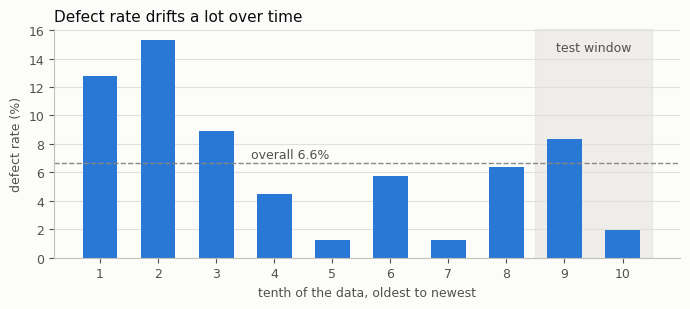

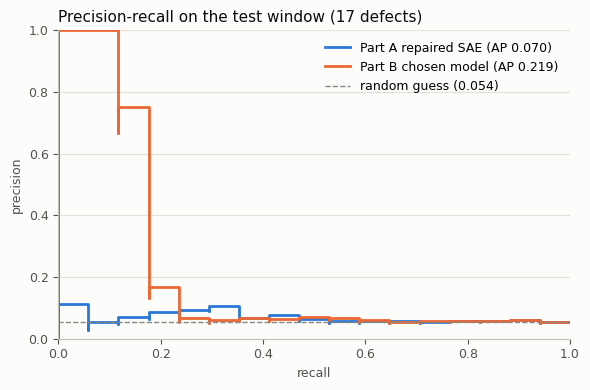

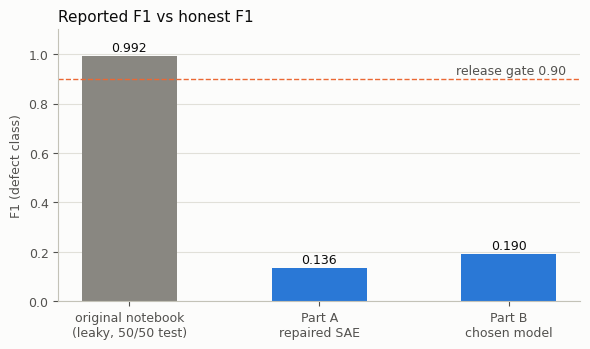

In [14]:
# colours: blue/orange are a colourblind-safe pair, grey dashed = reference lines
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID_C, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(axis="y", color=GRID_C, linewidth=0.8)
    ax.set_axisbelow(True)

# 1) defect rate over time
fig, ax = plt.subplots(figsize=(7, 3.2), facecolor=SURFACE)
ax.bar(range(1, 11), [r * 100 for r in decile_rates], color=BLUE, width=0.6)
ax.axhline(wu.NATURAL_PREVALENCE * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(3.6, wu.NATURAL_PREVALENCE * 100 + 0.4, "overall 6.6%", color=INK2, fontsize=9, ha="left")
ax.axvspan(8.5, 10.5, color=GRID_C, alpha=0.5, zorder=0)
ax.text(9.5, max(decile_rates) * 100 * 0.95, "test window", color=INK2, fontsize=9, ha="center")
ax.set_xticks(range(1, 11))
ax.set_xlabel("tenth of the data, oldest to newest", color=INK2, fontsize=9)
ax.set_ylabel("defect rate (%)", color=INK2, fontsize=9)
style(ax, "Defect rate drifts a lot over time")
plt.tight_layout(); plt.savefig("figures/defect_rate_over_time.png", dpi=150); plt.show()

# 2) PR curves on the test window
fig, ax = plt.subplots(figsize=(6, 4), facecolor=SURFACE)
for p, label, color in [(p_te_A, f"Part A repaired SAE (AP {res_A['ap']:.3f})", BLUE),
                        (p_te_B, f"Part B chosen model (AP {res_B['ap']:.3f})", ORANGE)]:
    prec, rec, _ = precision_recall_curve(y_te, p)
    ax.step(rec, prec, where="post", color=color, linewidth=2, label=label)
ax.axhline(y_te.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"random guess ({y_te.mean():.3f})")
ax.set_xlabel("recall", color=INK2, fontsize=9); ax.set_ylabel("precision", color=INK2, fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=9)
style(ax, "Precision-recall on the test window (17 defects)")
plt.tight_layout(); plt.savefig("figures/pr_curves_test.png", dpi=150); plt.show()

# 3) reported vs honest F1
ORIGINAL_F1 = 0.992   # from evidence/evidence_output.txt (original pipeline, scenario A)
labels = ["original notebook\n(leaky, 50/50 test)", "Part A\nrepaired SAE", "Part B\nchosen model"]
vals = [ORIGINAL_F1, res_A["f1"], res_B["f1"]]
fig, ax = plt.subplots(figsize=(6, 3.6), facecolor=SURFACE)
bars = ax.bar(labels, vals, color=[MUTED, BLUE, BLUE], width=0.5)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", color=INK, fontsize=9)
ax.axhline(0.90, color=ORANGE, linestyle="--", linewidth=1)
ax.text(2.3, 0.92, "release gate 0.90", color=INK2, fontsize=9, ha="right")
ax.set_ylim(0, 1.1); ax.set_ylabel("F1 (defect class)", color=INK2, fontsize=9)
style(ax, "Reported F1 vs honest F1")
plt.tight_layout(); plt.savefig("figures/f1_before_after.png", dpi=150); plt.show()

## 13. Release gate

In [15]:
GATE_F1 = 0.90
passed = res_B["f1"] >= GATE_F1
print(f"F1 on the natural-prevalence test window: {res_B['f1']:.4f} -> {'PASS' if passed else 'FAIL, NO-GO'}")

def to_json(r):
    return {k: float(v) for k, v in r.items()}

summary = dict(
    gate_passed=bool(passed),
    part_a=dict(threshold=THRESHOLD_A, test=to_json(res_A), baseline_logreg=to_json(res_lr_base),
                seeds=seed_df.round(4).to_dict(orient="records")),
    part_b=dict(config=BEST_CFG, threshold=THRESHOLD_B, test=to_json(res_B),
                reference_other=dict(config=OTHER_CFG, test=to_json(res_other)),
                no_legacy_ablation=dict(test=to_json(res_nl))),
)
with open("results/final_metrics.json", "w") as f:
    json.dump(summary, f, indent=2)

# the pipeline class lives in wafer_utils.py so this can be loaded anywhere with joblib.load
os.makedirs("artifacts", exist_ok=True)
joblib.dump(dict(pipeline=final_pipe, threshold=THRESHOLD_B), "artifacts/selected_pipeline.joblib")
print("saved results/final_metrics.json and artifacts/selected_pipeline.joblib")

F1 on the natural-prevalence test window: 0.1905 -> FAIL, NO-GO
saved results/final_metrics.json and artifacts/selected_pipeline.joblib
